# Évolution des cancers — étude statistique

Ce notebook reprend l'exploration initiale et corrige les manques identifiés :

- **Intervalle de confiance à 95 %** sur chaque pente de régression, pas juste la pente seule
- **Test de significativité** (p-value) : une pente peut être non nulle juste par bruit d'échantillonnage
- **R²** conservé pour juger la qualité du fit
- **Diagnostic des résidus** sur les deux tendances agrégées qui portent la conclusion du deck (groupe "lié pesticides" vs groupe "non lié")
- La liste des cancers "liés pesticides" est reprise du notebook d'origine, mais isolée et documentée pour qu'elle soit modifiable facilement

Variable étudiée : **Taux standardisés (Europe)**, pour neutraliser l'effet de structure d'âge de la population.

Limite qui reste entière et qu'aucun indicateur statistique ne corrige : le registre ne permet pas de contrôler le dépistage, le tabagisme ou l'obésité. Une tendance significative reste une corrélation temporelle, pas une preuve de lien causal aux pesticides.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

VARIABLE = "Taux standardisés (Europe)"
ALPHA = 0.05  # seuil de significativité

df = pd.read_excel("../data/table_tous.xlsx")
df = df[df["Sexe"] == "tous"].copy()
df["Localisation"] = df["Localisation"].str.strip()
print(df.shape)
df.head()

(560, 7)


,Localisation,Effectif,Taux,Taux standardisés (Europe),Taux standardisés (Monde),Année,Sexe
0,Sein,1697,94.0,69.4,51.1,2012,tous
1,Prostate,1606,89.0,54.9,37.4,2012,tous
2,Colon rectum,1412,78.2,43.2,28.9,2012,tous
3,"Poumon, bronche et trachée",1234,68.4,46.6,32.7,2012,tous
4,Lèvre-cavité orale-pharynx,442,24.5,18.3,13.2,2012,tous


## 1. Liste des cancers liés aux pesticides

Reprise du notebook d'exploration d'origine (`exploration_tous.ipynb`), basée sur le tableau de
présomption Inserm 2021 discuté dans la conversation "Pesticides et cancers : sources
scientifiques". À modifier ici si la liste doit évoluer — tout le reste du notebook en dépend.

**Correction apportée** : le notebook d'origine cherchait "Lymphome diffus à grandes cellules B",
qui ne matchait aucune ligne. Les données extraites des PDF du registre contiennent une coquille
d'OCR — "Lymphome di us à grandes cellules B" — qui faisait disparaître silencieusement ce cancer
du groupe "liés pesticides" (7 cancers comptés au lieu de 8). Corrigé ici en alignant la liste sur
le libellé réel des données ; l'idéal à terme est de corriger la coquille à la source, dans
`run_etl.py`.

In [2]:
PEST_LIST = [
    "Lymphome di us à grandes cellules B",  # coquille d'extraction OCR dans les données
                                             # source : "diffus" -> "di us" (perte du "ff")
    "Prostate",
    "Poumon, bronche et trachée",
    "Sein",
    "Myélome multiple et plasmocytome",
    "LLC / Lymphome lymphocytique",
    "Leucémie aiguë myéloïde",
    "Syndrome myélodysplasique",
]

def is_pest(loc):
    return any(p in loc for p in PEST_LIST)

df["lien_pesticide"] = df["Localisation"].apply(is_pest).astype("boolean")
df.loc[df["Localisation"].isin(["TOTAL", "Autres"]), "lien_pesticide"] = pd.NA

print(f"{df.loc[df['lien_pesticide']==True, 'Localisation'].nunique()} cancers classés 'liés pesticides'")
sorted(df.loc[df["lien_pesticide"] == True, "Localisation"].unique())

8 cancers classés 'liés pesticides'


['LLC / Lymphome lymphocytique',
 'Leucémie aiguë myéloïde',
 'Lymphome di us à grandes cellules B',
 'Myélome multiple et plasmocytome',
 'Poumon, bronche et trachée',
 'Prostate',
 'Sein',
 'Syndrome myélodysplasique']

In [3]:
# Coquille d'OCR d'extraction PDF ("diffus" -> "di us", perte du "ff") : le libellé brut est
# nécessaire pour matcher les lignes de `df`, mais ne doit jamais apparaître tel quel dans un
# titre de graphique ou un export destiné à être lu. DISPLAY_FIX corrige uniquement l'affichage.
DISPLAY_FIX = {"Lymphome di us à grandes cellules B": "Lymphome diffus à grandes cellules B"}


## 2. Fonction de régression avec indicateurs complets

Pour chaque série (année, taux), on calcule :

- la pente et son intervalle de confiance à 95 % (loi de Student, n-2 degrés de liberté)
- la p-value du test « la pente est-elle différente de 0 »
- le R²
- une étiquette de significativité

Avec seulement un point par an et par cancer, ces tests ont une puissance statistique limitée — une pente
« non significative » peut aussi juste refléter un manque de données, pas forcément une absence
réelle de tendance. C'est indiqué dans le tableau plutôt que masqué.

In [4]:
def regression_stats(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    res = stats.linregress(x, y)
    slope, intercept, r, p, se = res.slope, res.intercept, res.rvalue, res.pvalue, res.stderr
    t_crit = stats.t.ppf(1 - ALPHA / 2, df=n - 2)
    ci_low = slope - t_crit * se
    ci_high = slope + t_crit * se
    if p < ALPHA and slope > 0:
        label = "hausse significative"
    elif p < ALPHA and slope < 0:
        label = "baisse significative"
    else:
        label = "non significatif"
    return {
        "n": n,
        "pente": slope,
        "IC95_bas": ci_low,
        "IC95_haut": ci_high,
        "p_value": p,
        "r2": r ** 2,
        "significativite": label,
    }

## 3. Tableau des indicateurs, tous cancers

Un cancer par ligne, TOTAL et Autres exclus de l'analyse individuelle (TOTAL est traité à part en
section 5, Autres est un fourre-tout hétérogène qui n'a pas de sens à interpréter comme une
tendance).

In [5]:
rows = []
for loc, g in df[~df["Localisation"].isin(["TOTAL", "Autres"])].groupby("Localisation"):
    g = g.sort_values("Année")
    stats_dict = regression_stats(g["Année"], g[VARIABLE])
    rows.append({"Localisation": loc, "lien_pesticide": g["lien_pesticide"].iloc[0], **stats_dict})

summary = pd.DataFrame(rows).sort_values(["lien_pesticide", "p_value"], ascending=[False, True])
summary_display = summary.copy()
for c in ["pente", "IC95_bas", "IC95_haut", "p_value", "r2"]:
    summary_display[c] = summary_display[c].round(4)
summary_display

,Localisation,lien_pesticide,n,pente,IC95_bas,IC95_haut,p_value,r2,significativite
23,"Poumon, bronche et trachée",True,16,0.4434,0.2936,0.5931,0.0000,0.7423,hausse significative
7,Leucémie aiguë myéloïde,True,16,0.1225,0.0811,0.1639,0.0000,0.7422,hausse significative
26,Sein,True,16,0.4009,0.1518,0.6499,0.0039,0.4598,hausse significative
13,Lymphome di us à grandes cellules B,True,16,0.0518,0.0043,0.0992,0.0346,0.2812,hausse significative
18,Myélome multiple et plasmocytome,True,16,0.0359,-0.0162,0.0879,0.1613,0.1351,non significatif
5,LLC / Lymphome lymphocytique,True,16,0.0282,-0.0214,0.0778,0.2423,0.0962,non significatif
27,Syndrome myélodysplasique,True,16,0.0303,-0.0326,0.0932,0.3194,0.0708,non significatif
24,Prostate,True,16,-0.2293,-0.8931,0.4346,0.4711,0.0377,non significatif
22,Pancréas,False,16,0.2312,0.1529,0.3095,0.0000,0.7411,hausse significative
1,Colon rectum,False,16,-0.5144,-0.7072,-0.3216,0.0001,0.7005,baisse significative


In [6]:
# Combien de tendances sont réellement significatives, par groupe
summary.groupby(["lien_pesticide", "significativite"]).size().unstack(fill_value=0)

significativite,baisse significative,hausse significative,non significatif
lien_pesticide,,,
False,6,5,14
True,0,4,4


**Lecture** : seules les lignes avec `significativite != "non significatif"` supportent une
vraie affirmation de tendance. Les autres pentes, même positives ou négatives à l'œil, ne sont pas
distinguables du bruit avec un point par an.

## 4. Graphiques individuels, avec bande de confiance

Chaque graphique reprend le point de données, la droite de régression, et sa bande de confiance à
95 %. Le titre indique la significativité — c'est la façon la plus directe de voir d'un coup d'œil
quelles tendances sont solides.

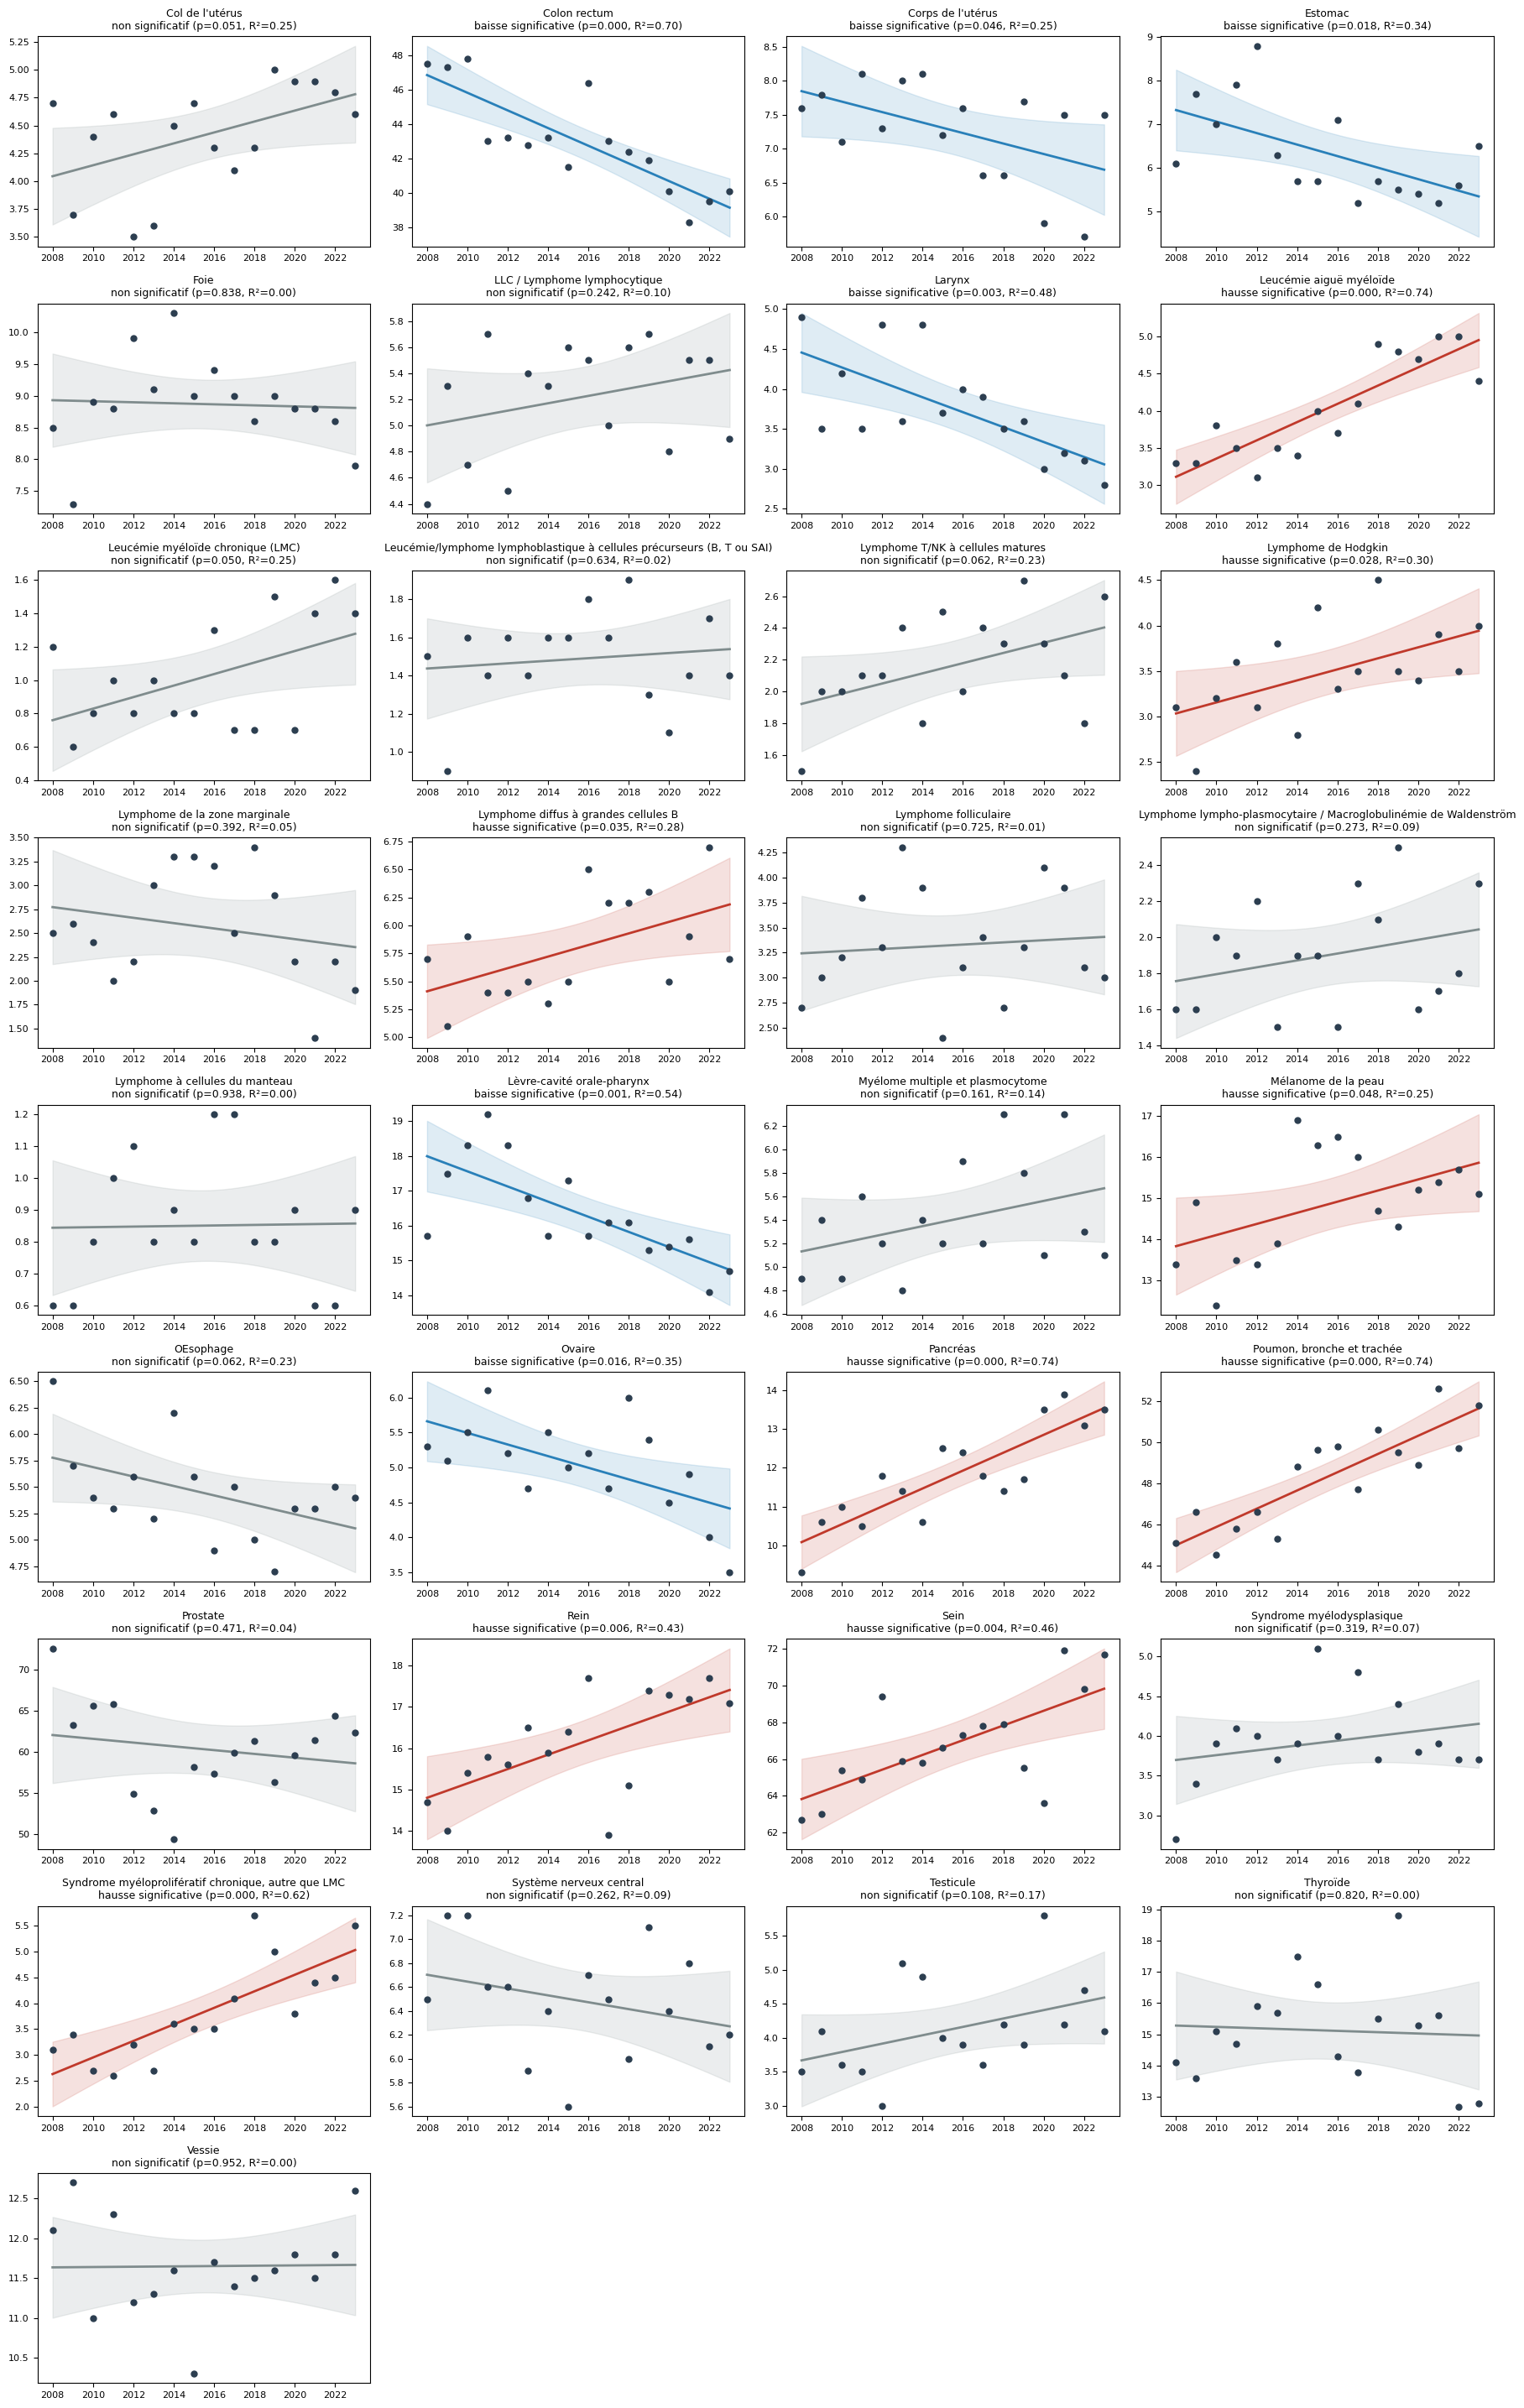

In [7]:
def plot_trend(ax, loc):
    g = df[df["Localisation"] == loc].sort_values("Année")
    x = g["Année"].values.astype(float)
    y = g[VARIABLE].values.astype(float)
    st = regression_stats(x, y)

    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = st["pente"] * x_fit + (y.mean() - st["pente"] * x.mean())

    # bande de confiance de la droite (pas juste de la pente) via l'erreur standard de prédiction
    n = len(x)
    x_mean = x.mean()
    s_err = np.sqrt(np.sum((y - (st["pente"] * x + (y.mean() - st["pente"] * x_mean))) ** 2) / (n - 2))
    se_fit = s_err * np.sqrt(1 / n + (x_fit - x_mean) ** 2 / np.sum((x - x_mean) ** 2))
    t_crit = stats.t.ppf(1 - ALPHA / 2, df=n - 2)

    color = {"hausse significative": "#c0392b", "baisse significative": "#2980b9",
             "non significatif": "#7f8c8d"}[st["significativite"]]

    ax.scatter(x, y, color="#2c3e50", s=25, zorder=3)
    ax.plot(x_fit, y_fit, color=color, linewidth=2)
    ax.fill_between(x_fit, y_fit - t_crit * se_fit, y_fit + t_crit * se_fit, color=color, alpha=0.15)
    label = DISPLAY_FIX.get(loc, loc)
    ax.set_title(f"{label}\n{st['significativite']} (p={st['p_value']:.3f}, R²={st['r2']:.2f})",
                 fontsize=9)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.tick_params(labelsize=8)

locs = sorted(df.loc[~df["Localisation"].isin(["TOTAL", "Autres"]), "Localisation"].unique())
n_cols = 4
n_rows = int(np.ceil(len(locs) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))
for ax, loc in zip(axes.flat, locs):
    plot_trend(ax, loc)
for ax in axes.flat[len(locs):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("../data/graphes_indicateurs_complets.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Comparaison agrégée : cancers liés pesticides vs non liés

C'est la comparaison qui porte la conclusion de la slide 3 du deck (« on tend vers 50-50 »). On
reprend ici la même logique que le notebook d'origine — sommer le taux standardisé sur les cancers
du groupe, par année — mais avec IC95 et p-value sur la pente de chaque groupe, plus un diagnostic
des résidus, puisque c'est le calcul qui doit être le plus solide de tout le document.

In [8]:
agg = (df[df["lien_pesticide"].notna()]
       .groupby(["Année", "lien_pesticide"])[VARIABLE]
       .sum()
       .reset_index())

pest = agg[agg["lien_pesticide"] == True].sort_values("Année")
non_pest = agg[agg["lien_pesticide"] == False].sort_values("Année")

st_pest = regression_stats(pest["Année"], pest[VARIABLE])
st_non_pest = regression_stats(non_pest["Année"], non_pest[VARIABLE])

pd.DataFrame([{"groupe": "liés pesticides", **st_pest},
              {"groupe": "non liés pesticides", **st_non_pest}]).round(4)

,groupe,n,pente,IC95_bas,IC95_haut,p_value,r2,significativite
0,liés pesticides,16,0.8837,0.1513,1.6161,0.0215,0.3236,hausse significative
1,non liés pesticides,16,-0.2703,-0.7507,0.2101,0.2475,0.0942,non significatif


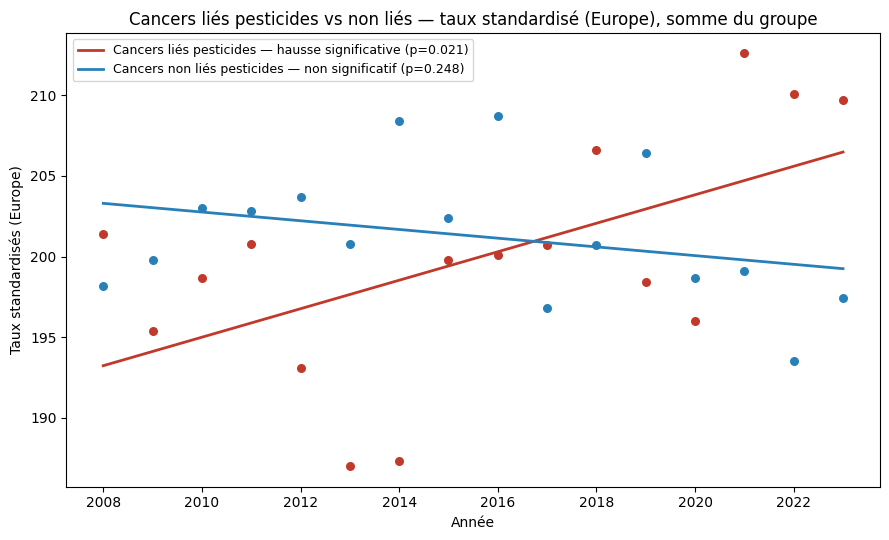

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for data, st, label, color in [
    (pest, st_pest, "Cancers liés pesticides", "#c0392b"),
    (non_pest, st_non_pest, "Cancers non liés pesticides", "#2980b9"),
]:
    x = data["Année"].values.astype(float)
    y = data[VARIABLE].values.astype(float)
    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = st["pente"] * x_fit + (y.mean() - st["pente"] * x.mean())
    ax.scatter(x, y, color=color, s=30)
    ax.plot(x_fit, y_fit, color=color, linewidth=2,
            label=f"{label} — {st['significativite']} (p={st['p_value']:.3f})")

ax.set_xlabel("Année")
ax.set_ylabel(VARIABLE)
ax.legend(fontsize=9)
ax.set_title("Cancers liés pesticides vs non liés — taux standardisé (Europe), somme du groupe")
plt.tight_layout()
plt.savefig("../data/comparaison_groupes_indicateurs_complets.png", dpi=150, bbox_inches="tight")
plt.show()

### Diagnostic des résidus, groupe par groupe

Trois vérifications : les résidus sont-ils centrés sans motif visible, à peu près normaux (test de
Shapiro-Wilk), et non autocorrélés (test de Durbin-Watson, important ici puisque c'est une série
temporelle). Avec si peu de points, ces tests ont une puissance faible — à lire comme un signal
d'alerte, pas comme une validation définitive.

--- Liés pesticides ---
Shapiro-Wilk p-value (normalité) : 0.234 -> résidus proches de la normale
Durbin-Watson : 1.25 -> autocorrélation possible, prudence sur la p-value
--- Non liés pesticides ---
Shapiro-Wilk p-value (normalité) : 0.240 -> résidus proches de la normale
Durbin-Watson : 1.89 -> pas d’autocorrélation marquée


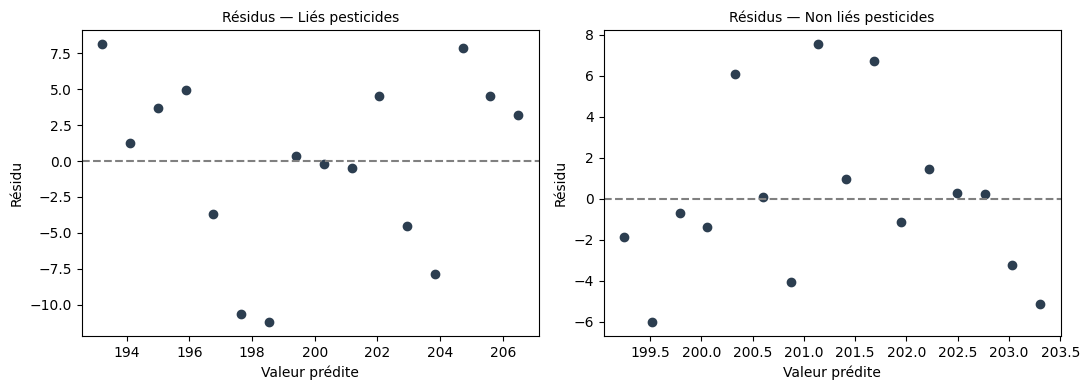

In [10]:
def residual_diagnostics(data, label):
    x = data["Année"].values.astype(float)
    y = data[VARIABLE].values.astype(float)
    slope, intercept, *_ = stats.linregress(x, y)
    y_pred = slope * x + intercept
    resid = y - y_pred

    shapiro_p = stats.shapiro(resid).pvalue
    dw = np.sum(np.diff(resid) ** 2) / np.sum(resid ** 2)  # Durbin-Watson

    print(f"--- {label} ---")
    print(f"Shapiro-Wilk p-value (normalité) : {shapiro_p:.3f}"
          f" -> {'résidus proches de la normale' if shapiro_p > ALPHA else 'écart à la normalité détecté'}")
    print(f"Durbin-Watson : {dw:.2f}"
          f" -> {'pas d’autocorrélation marquée' if 1.5 < dw < 2.5 else 'autocorrélation possible, prudence sur la p-value'}")
    return resid, y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (data, label) in zip(axes, [(pest, "Liés pesticides"), (non_pest, "Non liés pesticides")]):
    resid, y_pred = residual_diagnostics(data, label)
    ax.scatter(y_pred, resid, color="#2c3e50")
    ax.axhline(0, color="grey", linestyle="--")
    ax.set_title(f"Résidus — {label}", fontsize=10)
    ax.set_xlabel("Valeur prédite")
    ax.set_ylabel("Résidu")
plt.tight_layout()
plt.show()

## 6. Tendance globale (TOTAL)

Même traitement pour la courbe TOTAL du deck, qui donne le chiffre « +20 % en 15 ans » de la slide 1.

In [11]:
total = df[df["Localisation"] == "TOTAL"].sort_values("Année")
st_total = regression_stats(total["Année"], total[VARIABLE])
st_total_display = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in st_total.items()}
st_total_display

{'n': 16,
 'pente': np.float64(0.7521),
 'IC95_bas': np.float64(0.0294),
 'IC95_haut': np.float64(1.4747),
 'p_value': np.float64(0.0425),
 'r2': np.float64(0.2625),
 'significativite': 'hausse significative'}

## 7. Export

Le tableau complet des indicateurs, pour réinjection dans le PowerPoint ou dans un futur tableau de
synthèse.

In [12]:
summary.to_excel("../data/indicateurs_regression_tous_cancers.xlsx", index=False)
print("Exporté : data/indicateurs_regression_tous_cancers.xlsx")

Exporté : data/indicateurs_regression_tous_cancers.xlsx


## 8. Classification élargie par niveau de présomption (Inserm 2021)

La liste de 8 cancers utilisée plus haut ne reprenait qu'une petite partie des cancers à
présomption forte listés par l'expertise collective Inserm 2021 — notamment 2 des 7 sous-types
de lymphome non hodgkinien. Cette section reprend la classification complète, en 3 niveaux :

- **Forte** : 11 cancers, dont les 7 sous-types de LNH, la prostate, le myélome multiple, le
  système nerveux central et la leucémie/lymphome lymphoblastique (forts chez l'enfant)
- **Moyenne** : 12 cancers, dont le sein, le poumon, le rein, la vessie, le côlon-rectum...
- **Non liée** : les 10 cancers restants du registre, non documentés ou insuffisamment étudiés

Sources détaillées par cancer en section 10.

In [13]:
FORTE = [
    "Prostate", "Myélome multiple et plasmocytome", "LLC / Lymphome lymphocytique",
    "Lymphome di us à grandes cellules B", "Lymphome folliculaire",
    "Lymphome à cellules du manteau", "Lymphome de la zone marginale",
    "Lymphome T/NK à cellules matures",
    "Lymphome lympho-plasmocytaire / Macroglobulinémie de Waldenström",
    "Système nerveux central",
    "Leucémie/lymphome lymphoblastique à cellules précurseurs (B, T ou SAI)",
]
MOYENNE = [
    "Sein", "Poumon, bronche et trachée", "Leucémie aiguë myéloïde",
    "Syndrome myélodysplasique", "Rein", "Vessie", "Colon rectum",
    "Mélanome de la peau", "Testicule", "Ovaire", "Pancréas", "Thyroïde",
]
ALL_PEST = FORTE + MOYENNE
assert len(set(ALL_PEST)) == len(ALL_PEST) == 23

df["presomption"] = "Non liée"
df.loc[df["Localisation"].isin(FORTE), "presomption"] = "Forte"
df.loc[df["Localisation"].isin(MOYENNE), "presomption"] = "Moyenne"
df.loc[df["Localisation"].isin(["TOTAL", "Autres"]), "presomption"] = pd.NA

df["presomption"].value_counts(dropna=False)

presomption
Moyenne     192
Forte       176
Non liée    160
<NA>         32
Name: count, dtype: int64

### 8.1 Indicateurs pour les 23 cancers, par niveau de présomption

In [14]:
rows_pres = []
for loc, g in df[df["presomption"].notna()].groupby("Localisation"):
    g = g.sort_values("Année")
    st = regression_stats(g["Année"], g[VARIABLE])
    rows_pres.append({"Localisation": loc, "presomption": g["presomption"].iloc[0], **st})

summary_pres = pd.DataFrame(rows_pres).sort_values(["presomption", "p_value"])
summary_pres.groupby(["presomption", "significativite"]).size().unstack(fill_value=0)

significativite,baisse significative,hausse significative,non significatif
presomption,,,
Forte,0,1,10
Moyenne,2,6,4
Non liée,4,2,4


### 8.2 Comparaison indice base 100 : liés (23) vs non liés (10)

Sommer un taux standardisé sur des groupes de taille très différente (23 cancers vs 10) écrase
le graphique : le groupe le plus nombreux domine visuellement même sans écart réel. On indexe
donc chaque groupe à 100 en 2008 pour comparer des **croissances**, pas des niveaux.

Liés pesticides (23 cancers): hausse significative, p=0.007, IC95 pente=[0.08, 0.44]
Non liés (10 cancers): baisse significative, p=0.025, IC95 pente=[-0.81, -0.06]


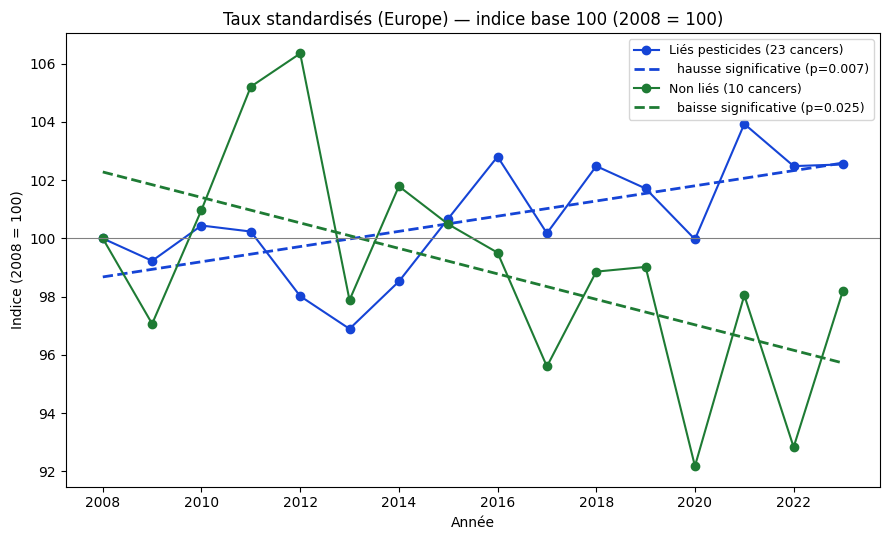

In [15]:
agg = (df[df["presomption"].notna()]
       .assign(lien=lambda d: d["presomption"] != "Non liée")
       .groupby(["Année", "lien"])[VARIABLE].mean().reset_index())
pest = agg[agg["lien"] == True].sort_values("Année")
non_pest = agg[agg["lien"] == False].sort_values("Année")

fig, ax = plt.subplots(figsize=(9, 5.5))
for data, label, color in [(pest, "Liés pesticides (23 cancers)", "#1544D6"),
                            (non_pest, "Non liés (10 cancers)", "#1E7B34")]:
    x = data["Année"].values.astype(float)
    y = data[VARIABLE].values.astype(float)
    y_idx = y / y[0] * 100
    st = regression_stats(x, y_idx)
    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = st["pente"] * x_fit + (y_idx.mean() - st["pente"] * x.mean())
    ax.plot(x, y_idx, "o-", color=color, label=f"{label}")
    ax.plot(x_fit, y_fit, color=color, linewidth=2, linestyle="--",
            label=f"  {st['significativite']} (p={st['p_value']:.3f})")
    print(f"{label}: {st['significativite']}, p={st['p_value']:.3f}, "
          f"IC95 pente=[{st['IC95_bas']:.2f}, {st['IC95_haut']:.2f}]")

ax.axhline(100, color="grey", linewidth=0.8)
ax.set_xlabel("Année")
ax.set_ylabel("Indice (2008 = 100)")
ax.set_title(f"{VARIABLE} — indice base 100 ({int(pest['Année'].min())} = 100)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../data/comparaison_indice_base100.png", dpi=150, bbox_inches="tight")
plt.show()

**Résultat** : avec le périmètre complet (23 cancers), l'écart entre les deux groupes
devient statistiquement significatif — hausse pour les cancers liés, baisse pour les non liés.
Avec la sélection initiale à 8 cancers (section 5), le même écart n'était pas significatif.
La classification complète change donc la conclusion, pas seulement les chiffres.

### 8.3 Même comparaison, sans standardisation par âge (taux brut)

Le taux « standardisé (Europe) » neutralise l'effet du vieillissement de la population : il
recalcule l'incidence que l'on observerait si la pyramide des âges de Poitou-Charentes était
identique à celle de la population européenne de référence. Pour vérifier que la divergence entre
les deux groupes ne vient pas uniquement de cet ajustement, on refait le même calcul avec le taux
brut (`Taux`), non corrigé de l'âge.

Liés pesticides (23 cancers): hausse significative, p=0.000, IC95 pente=[1.29, 1.76]
Non liés (10 cancers): hausse significative, p=0.008, IC95 pente=[0.18, 0.97]


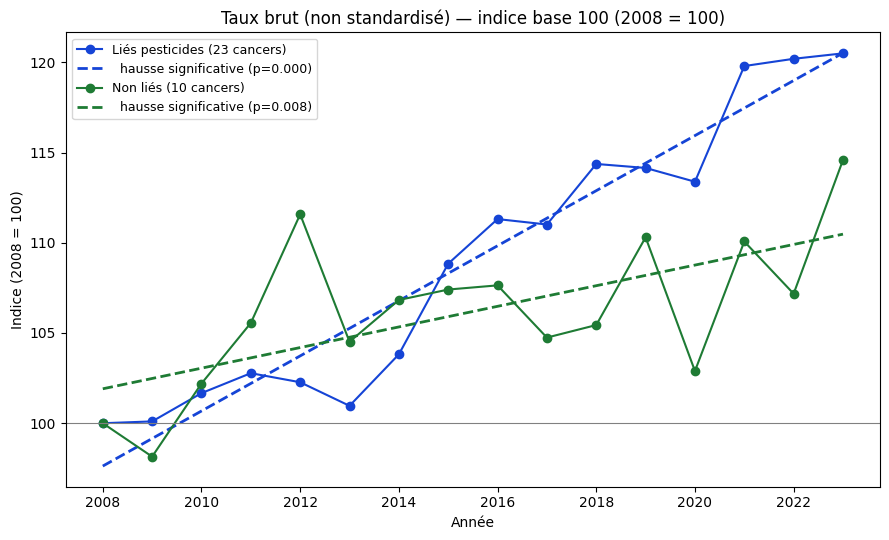

In [16]:
agg_brut = (df[df["presomption"].notna()]
       .assign(lien=lambda d: d["presomption"] != "Non liée")
       .groupby(["Année", "lien"])["Taux"].mean().reset_index())
pest_brut = agg_brut[agg_brut["lien"] == True].sort_values("Année")
non_pest_brut = agg_brut[agg_brut["lien"] == False].sort_values("Année")

fig, ax = plt.subplots(figsize=(9, 5.5))
stats_brut = {}
for data, label, color, key in [(pest_brut, "Liés pesticides (23 cancers)", "#1544D6", "lies_pesticides"),
                                 (non_pest_brut, "Non liés (10 cancers)", "#1E7B34", "non_lies_pesticides")]:
    x = data["Année"].values.astype(float)
    y = data["Taux"].values.astype(float)
    y_idx = y / y[0] * 100
    st = regression_stats(x, y_idx)
    stats_brut[key] = st
    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = st["pente"] * x_fit + (y_idx.mean() - st["pente"] * x.mean())
    ax.plot(x, y_idx, "o-", color=color, label=f"{label}")
    ax.plot(x_fit, y_fit, color=color, linewidth=2, linestyle="--",
            label=f"  {st['significativite']} (p={st['p_value']:.3f})")
    print(f"{label}: {st['significativite']}, p={st['p_value']:.3f}, "
          f"IC95 pente=[{st['IC95_bas']:.2f}, {st['IC95_haut']:.2f}]")

ax.axhline(100, color="grey", linewidth=0.8)
ax.set_xlabel("Année")
ax.set_ylabel("Indice (2008 = 100)")
ax.set_title(f"Taux brut (non standardisé) — indice base 100 ({int(pest_brut['Année'].min())} = 100)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../data/comparaison_indice_base100_taux_brut.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Grilles par niveau de présomption

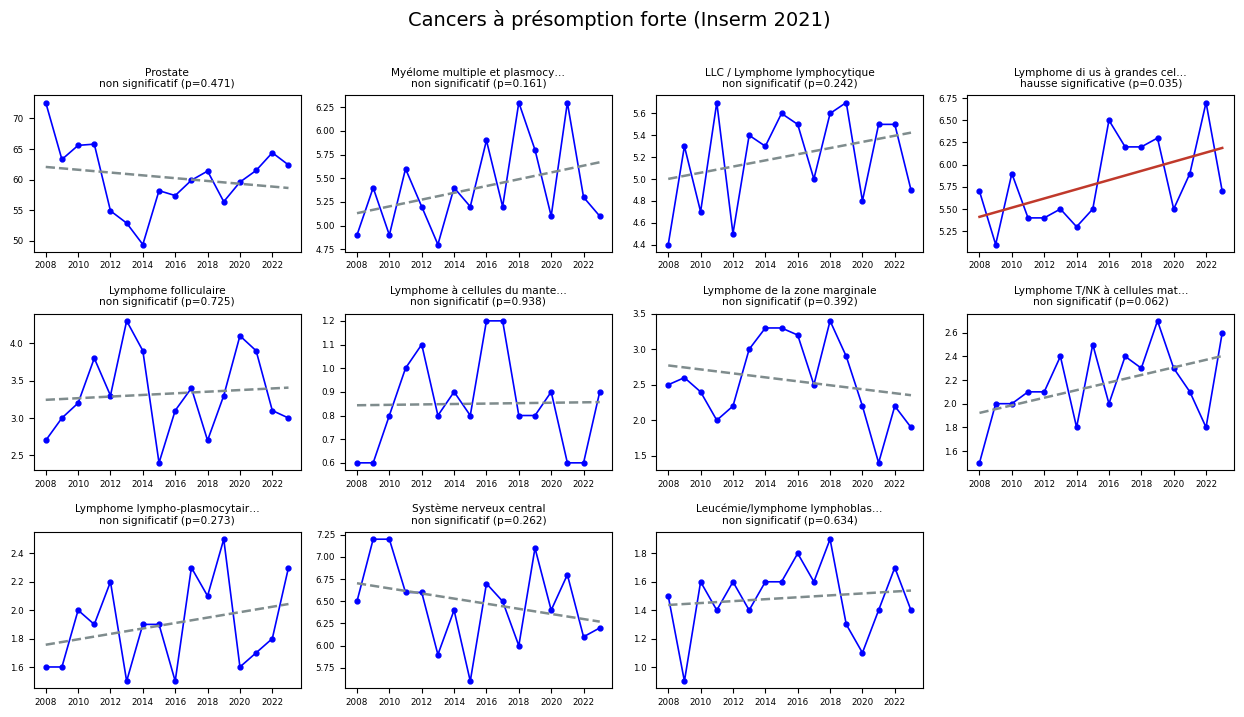

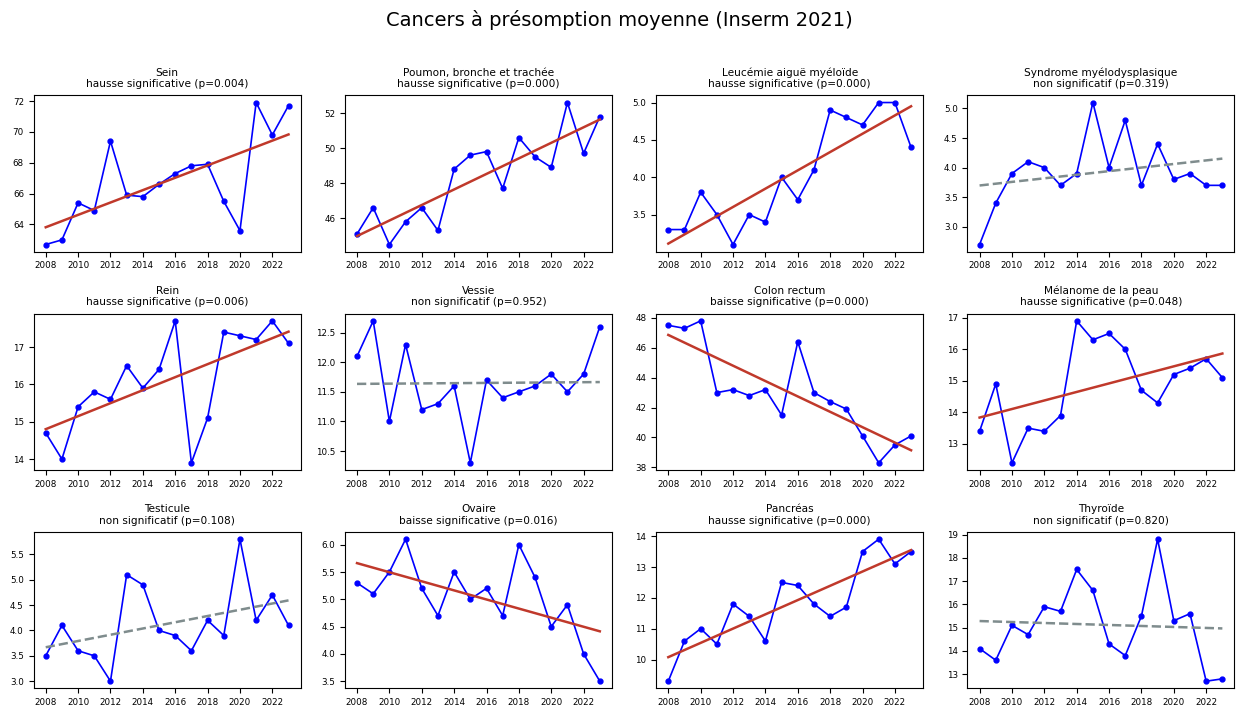

In [17]:
def make_grid(cancer_list, title, ncols=4):
    nrows = int(np.ceil(len(cancer_list) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.15, nrows * 2.35))
    axes = np.atleast_2d(axes)
    for i, cancer in enumerate(cancer_list):
        r, c = divmod(i, ncols)
        ax = axes[r, c]
        g = df[df["Localisation"] == cancer].sort_values("Année")
        x, y = g["Année"].values.astype(float), g[VARIABLE].values.astype(float)
        st = regression_stats(x, y)
        x_fit = np.linspace(x.min(), x.max(), 100)
        y_fit = st["pente"] * x_fit + (y.mean() - st["pente"] * x.mean())
        color = "#C0392B" if st["significativite"] != "non significatif" else "#7F8C8D"
        ls = "-" if st["significativite"] != "non significatif" else "--"
        ax.plot(x, y, "o-", color="blue", markersize=3.5, linewidth=1.2)
        ax.plot(x_fit, y_fit, color=color, linewidth=1.8, linestyle=ls)
        label = cancer if len(cancer) < 30 else cancer[:28] + "…"
        ax.set_title(f"{label}\n{st['significativite']} (p={st['p_value']:.3f})", fontsize=7.6)
        ax.tick_params(labelsize=6.3)
    for i in range(len(cancer_list), nrows * ncols):
        r, c = divmod(i, ncols)
        axes[r, c].axis("off")
    fig.suptitle(title, fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

make_grid(FORTE, "Cancers à présomption forte (Inserm 2021)")
make_grid(MOYENNE, "Cancers à présomption moyenne (Inserm 2021)")

## 10. Tableau complet, sources par cancer

Sources détaillées, classées par niveau de présomption. Réutilisé pour la diapo "Tableau complet
et sources" du PowerPoint.

In [18]:
SOURCE_NOTE = {
    "Prostate": "Inserm 2021, présomption forte",
    "Myélome multiple et plasmocytome": "Inserm 2021, présomption forte",
    "LLC / Lymphome lymphocytique": "Inserm 2021, LNH forte",
    "Lymphome di us à grandes cellules B": "Inserm 2021, LNH forte",
    "Lymphome folliculaire": "Inserm 2021, LNH forte",
    "Lymphome à cellules du manteau": "Inserm 2021, LNH forte",
    "Lymphome de la zone marginale": "Inserm 2021, LNH forte",
    "Lymphome T/NK à cellules matures": "Inserm 2021, LNH forte",
    "Lymphome lympho-plasmocytaire / Macroglobulinémie de Waldenström": "Inserm 2021, LNH forte",
    "Système nerveux central": "Inserm 2021, fort chez l'enfant",
    "Leucémie/lymphome lymphoblastique à cellules précurseurs (B, T ou SAI)": "Inserm 2021, fort chez l'enfant",
    "Sein": "Inserm/INRAE/Cnam, cocktails alimentaires",
    "Poumon, bronche et trachée": "Agricultural Health Study ; ARC",
    "Leucémie aiguë myéloïde": "Inserm 2021 ; thèse 2021, OR = 1,51 chez l'adulte",
    "Syndrome myélodysplasique": "ScienceDirect 2023, preuves limitées",
    "Rein": "Inserm 2021, présomption moyenne",
    "Vessie": "Inserm 2021, présomption moyenne",
    "Colon rectum": "Inserm 2021, AGRICAN ; piclorame 2026",
    "Mélanome de la peau": "Ligue contre le cancer ; JCO 2025",
    "Testicule": "Ligue contre le cancer, d'après Inserm 2021",
    "Ovaire": "Fondation ARC ; Cancer-Environnement",
    "Pancréas": "Études PESTIPAC/EcoPESTIPAC",
    "Thyroïde": "Inserm 2021, présomption moyenne",
}
NON_LIEE_NOTE = {
    "Col de l'utérus": "Non documenté", "Corps de l'utérus": "Non documenté",
    "OEsophage": "Données insuffisantes, Inserm", "Estomac": "Données insuffisantes, Inserm",
    "Foie": "Données insuffisantes, Inserm", "Larynx": "Non documenté",
    "Lèvre-cavité orale-pharynx": "Données insuffisantes, cancers ORL",
    "Leucémie myéloïde chronique (LMC)": "Non documenté",
    "Syndrome myéloprolifératif chronique, autre que LMC": "Non documenté",
    "Lymphome de Hodgkin": "Non documenté, contrairement aux LNH",
}

rows_full = []
for cancer in sorted(FORTE + MOYENNE + list(NON_LIEE_NOTE.keys())):
    g = df[df["Localisation"] == cancer].sort_values("Année")
    st = regression_stats(g["Année"], g[VARIABLE])
    pres = "Forte" if cancer in FORTE else "Moyenne" if cancer in MOYENNE else "Non liée"
    source = SOURCE_NOTE.get(cancer) or NON_LIEE_NOTE.get(cancer)
    rows_full.append([cancer, pres, st["significativite"], round(st["p_value"], 4), source])

table_complete = pd.DataFrame(rows_full, columns=["Cancer", "Présomption", "Tendance", "p_value", "Source"])
table_complete = table_complete.sort_values(["Présomption", "Cancer"],
    key=lambda s: s.map({"Forte": 0, "Moyenne": 1, "Non liée": 2}) if s.name == "Présomption" else s)
table_complete.to_excel("../data/tableau_complet_sources.xlsx", index=False)
table_complete

,Cancer,Présomption,Tendance,p_value,Source
5,LLC / Lymphome lymphocytique,Forte,non significatif,0.2423,"Inserm 2021, LNH forte"
9,Leucémie/lymphome lymphoblastique à cellules p...,Forte,non significatif,0.6344,"Inserm 2021, fort chez l'enfant"
10,Lymphome T/NK à cellules matures,Forte,non significatif,0.0619,"Inserm 2021, LNH forte"
12,Lymphome de la zone marginale,Forte,non significatif,0.3924,"Inserm 2021, LNH forte"
13,Lymphome di us à grandes cellules B,Forte,hausse significative,0.0346,"Inserm 2021, LNH forte"
14,Lymphome folliculaire,Forte,non significatif,0.7248,"Inserm 2021, LNH forte"
15,Lymphome lympho-plasmocytaire / Macroglobuliné...,Forte,non significatif,0.2729,"Inserm 2021, LNH forte"
16,Lymphome à cellules du manteau,Forte,non significatif,0.9385,"Inserm 2021, LNH forte"
18,Myélome multiple et plasmocytome,Forte,non significatif,0.1613,"Inserm 2021, présomption forte"
24,Prostate,Forte,non significatif,0.4711,"Inserm 2021, présomption forte"


## 11. Analyse par sexe (exploratoire, non publiée)

Section de travail : ses résultats ne sont pas exportés vers le site. Leur interprétation fait
intervenir des facteurs propres à chaque sexe (tabagisme, dépistage) que le registre ne renseigne
pas ; le site se contente de signaler, dans ses limites, que les évolutions diffèrent selon le sexe.

Même méthode que ci-dessus (taux standardisé Europe, classification Inserm 2021, comparaison
indexée base 100), appliquée séparément aux tableaux "Chez les hommes" et "Chez les femmes" du
registre. Les cancers propres à un sexe n'apparaissent que dans le tableau concerné : prostate et
testicule chez les hommes, sein, ovaire, col et corps de l'utérus chez les femmes (le registre ne
publie pas de ligne "Sein" chez les hommes). Les deux groupes ne comptent donc pas le même nombre
de cancers selon le sexe.

Limite propre à cette section : découper par sexe divise les effectifs par deux environ. Pour les
cancers rares (LMC, lymphome à cellules du manteau, larynx chez les femmes : parfois moins de 10
cas par an), le taux annuel est très bruité et la régression a encore moins de puissance.

In [19]:
SEXES = {"hommes": "Hommes", "femmes": "Femmes"}
PRES_ORDER = {"Forte": 0, "Moyenne": 1, "Non liée": 2}

def load_sexe(sexe):
    d = pd.read_excel(f"../data/table_{sexe}.xlsx")
    d = d[d["Sexe"] == sexe].copy()
    d["Localisation"] = d["Localisation"].str.strip()
    d["presomption"] = "Non liée"
    d.loc[d["Localisation"].isin(FORTE), "presomption"] = "Forte"
    d.loc[d["Localisation"].isin(MOYENNE), "presomption"] = "Moyenne"
    d.loc[d["Localisation"].isin(["TOTAL", "Autres"]), "presomption"] = pd.NA
    # tout libellé du registre doit être classé explicitement, sinon il tomberait en "Non liée"
    # sans qu'on le voie
    connus = set(FORTE) | set(MOYENNE) | set(NON_LIEE_NOTE) | {"TOTAL", "Autres"}
    inconnus = set(d["Localisation"]) - connus
    assert not inconnus, f"Localisations non classées ({sexe}) : {inconnus}"
    return d

def groupes_base100(d, variable):
    """Moyenne du taux par groupe (liés / non liés) et par année, indexée à 100 la première année."""
    agg = (d[d["presomption"].notna()]
           .assign(lien=lambda x: x["presomption"] != "Non liée")
           .groupby(["Année", "lien"])[variable].mean().reset_index())
    series, st = {}, {}
    for lien_val, key in [(True, "lies_pesticides"), (False, "non_lies_pesticides")]:
        g = agg[agg["lien"] == lien_val].sort_values("Année")
        y = g[variable].values.astype(float)
        y_idx = y / y[0] * 100
        series[key] = (g["Année"].values.astype(float), y_idx)
        st[key] = regression_stats(g["Année"], y_idx)
    return series, st

par_sexe, series_sexe = {}, {}
for sexe in SEXES:
    d = load_sexe(sexe)
    cancers = []
    for loc, g in d[d["presomption"].notna()].groupby("Localisation"):
        g = g.sort_values("Année")
        cancers.append({"nom": DISPLAY_FIX.get(loc, loc), "presomption": g["presomption"].iloc[0],
                        **regression_stats(g["Année"], g[VARIABLE])})
    cancers.sort(key=lambda c: (PRES_ORDER[c["presomption"]], c["nom"]))
    s_std, st_std = groupes_base100(d, VARIABLE)
    s_brut, st_brut = groupes_base100(d, "Taux")
    total = d[d["Localisation"] == "TOTAL"].sort_values("Année")
    par_sexe[sexe] = {
        "n_lies": sum(c["presomption"] != "Non liée" for c in cancers),
        "n_non_lies": sum(c["presomption"] == "Non liée" for c in cancers),
        "total": regression_stats(total["Année"], total[VARIABLE]),
        "groupes": st_std,
        "groupes_taux_brut": st_brut,
        "cancers": cancers,
    }
    series_sexe[sexe] = {"std": s_std, "brut": s_brut}

pd.DataFrame([{"sexe": s, "groupe": k, **v}
              for s, ps in par_sexe.items()
              for k, v in [("TOTAL", ps["total"]),
                           (f"liés ({ps['n_lies']})", ps["groupes"]["lies_pesticides"]),
                           (f"non liés ({ps['n_non_lies']})", ps["groupes"]["non_lies_pesticides"]),
                           (f"liés, taux brut", ps["groupes_taux_brut"]["lies_pesticides"]),
                           (f"non liés, taux brut", ps["groupes_taux_brut"]["non_lies_pesticides"])]]
            ).round(4)

,sexe,groupe,n,pente,IC95_bas,IC95_haut,p_value,r2,significativite
0,hommes,TOTAL,16,-1.1910,-2.4734,0.0914,0.0663,0.2208,non significatif
1,hommes,liés (21),16,-0.1416,-0.4584,0.1753,0.3543,0.0615,non significatif
2,hommes,non liés (8),16,-0.8909,-1.3832,-0.3987,0.0017,0.5184,baisse significative
3,hommes,"liés, taux brut",16,1.3677,0.9742,1.7611,0.0000,0.7988,hausse significative
4,hommes,"non liés, taux brut",16,0.2330,-0.2746,0.7405,0.3416,0.0647,non significatif
5,femmes,TOTAL,16,2.4528,1.5737,3.3318,0.0000,0.7190,hausse significative
6,femmes,liés (21),16,0.7952,0.5584,1.0320,0.0000,0.7875,hausse significative
7,femmes,non liés (10),16,0.2913,-0.2938,0.8764,0.3037,0.0753,non significatif
8,femmes,"liés, taux brut",16,1.7412,1.5004,1.9821,0.0000,0.9450,hausse significative
9,femmes,"non liés, taux brut",16,1.0720,0.4476,1.6964,0.0025,0.4920,hausse significative


### 11.1 Comparaison indexée base 100, par sexe

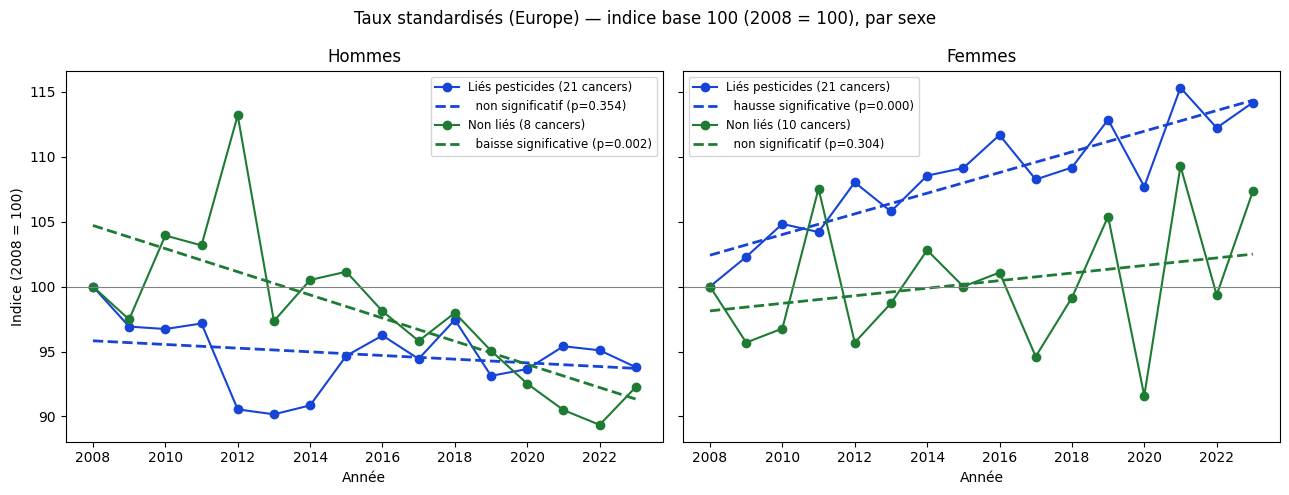

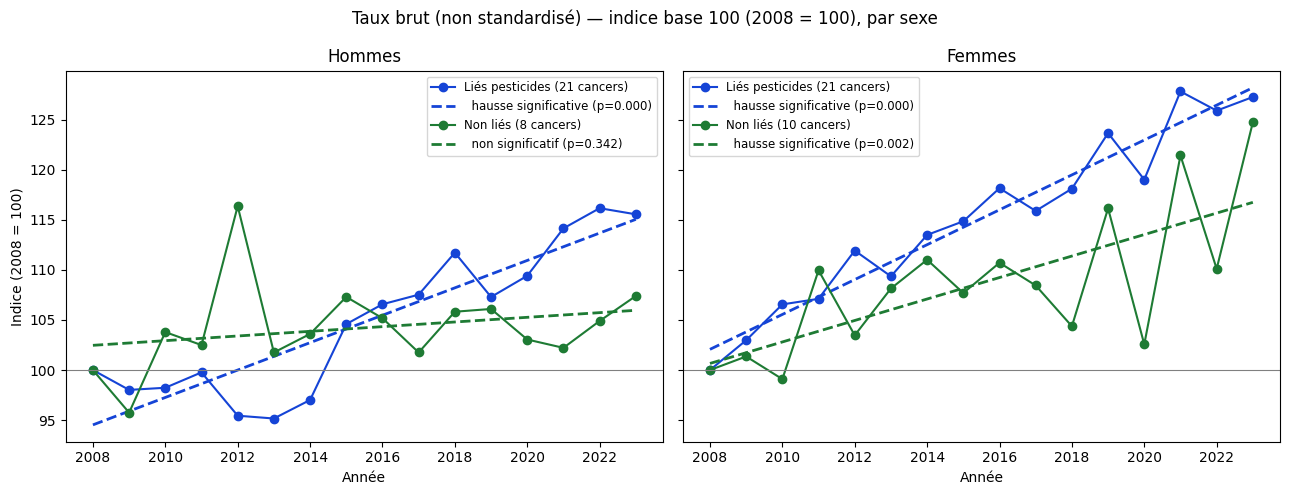

In [20]:
def plot_base100_par_sexe(kind, ylabel_var, path):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, (sexe, titre) in zip(axes, SEXES.items()):
        ps = par_sexe[sexe]
        st_groupes = ps["groupes"] if kind == "std" else ps["groupes_taux_brut"]
        for key, label, color in [("lies_pesticides", f"Liés pesticides ({ps['n_lies']} cancers)", "#1544D6"),
                                  ("non_lies_pesticides", f"Non liés ({ps['n_non_lies']} cancers)", "#1E7B34")]:
            x, y_idx = series_sexe[sexe][kind][key]
            st = st_groupes[key]
            x_fit = np.linspace(x.min(), x.max(), 100)
            y_fit = st["pente"] * x_fit + (y_idx.mean() - st["pente"] * x.mean())
            ax.plot(x, y_idx, "o-", color=color, label=label)
            ax.plot(x_fit, y_fit, color=color, linewidth=2, linestyle="--",
                    label=f"  {st['significativite']} (p={st['p_value']:.3f})")
        ax.axhline(100, color="grey", linewidth=0.8)
        ax.set_title(titre)
        ax.set_xlabel("Année")
        ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
        ax.legend(fontsize=8.5)
    y0 = int(df["Année"].min())
    axes[0].set_ylabel(f"Indice ({y0} = 100)")
    fig.suptitle(f"{ylabel_var} — indice base 100 ({y0} = 100), par sexe")
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

plot_base100_par_sexe("std", VARIABLE, "../data/comparaison_indice_base100_par_sexe.png")
plot_base100_par_sexe("brut", "Taux brut (non standardisé)", "../data/comparaison_indice_base100_taux_brut_par_sexe.png")

### 11.2 Tendance par cancer : tous sexes, hommes, femmes

Vue côte à côte des significativités, pour repérer les cancers dont la tendance d'ensemble est
portée par un seul sexe, ou masque des évolutions opposées.

In [21]:
def sig_court(label):
    return {"hausse significative": "↑", "baisse significative": "↓", "non significatif": "–"}[label]

rows = []
for r in table_complete.to_dict("records"):
    nom = DISPLAY_FIX.get(r["Cancer"], r["Cancer"])
    row = {"Cancer": nom, "Présomption": r["Présomption"], "Tous": sig_court(r["Tendance"])}
    for sexe, titre in SEXES.items():
        m = {c["nom"]: c["significativite"] for c in par_sexe[sexe]["cancers"]}
        row[titre] = sig_court(m[nom]) if nom in m else ""
    rows.append(row)
comparaison_sexes = pd.DataFrame(rows)
comparaison_sexes

,Cancer,Présomption,Tous,Hommes,Femmes
0,LLC / Lymphome lymphocytique,Forte,–,–,–
1,Leucémie/lymphome lymphoblastique à cellules p...,Forte,–,–,–
2,Lymphome T/NK à cellules matures,Forte,–,↑,–
3,Lymphome de la zone marginale,Forte,–,–,–
4,Lymphome diffus à grandes cellules B,Forte,↑,–,↑
5,Lymphome folliculaire,Forte,–,–,–
6,Lymphome lympho-plasmocytaire / Macroglobuliné...,Forte,–,–,–
7,Lymphome à cellules du manteau,Forte,–,–,–
8,Myélome multiple et plasmocytome,Forte,–,–,↑
9,Prostate,Forte,–,–,


## 12. Comparaison avec la v1 de l'étude

La v1 de l'étude, publiée sur le site, portait sur les données du registre disponibles jusqu'à
2022. Entre la v1 et la v2, les données changent de deux façons : le registre ajoute une année, et
il republie les années précédentes avec des effectifs révisés. Pour séparer les deux effets, on
compare trois calculs, avec exactement la même méthode :

1. **v1** : résultats publiés, figés dans `data/v1/site_stats.json` (données de l'époque dans
   `data/v1/table_tous.xlsx`) ;
2. **données révisées, période v1** : les données actuelles, restreintes à la période de la v1 —
   l'écart avec (1) ne vient que des révisions du registre ;
3. **v2** : les données actuelles sur toute la période — l'écart avec (2) ne vient que de l'année
   ajoutée.

Seuls les indicateurs affichés sur le site sont comparés : les deux comparaisons de groupes
(taux standardisé et taux brut) et la tendance de chaque cancer.

In [22]:
import json

with open("../data/v1/site_stats.json", encoding="utf-8") as f:
    v1 = json.load(f)
v1_max = v1["annees"]["max"]
df_v1 = pd.read_excel("../data/v1/table_tous.xlsx")
df_v1 = df_v1[df_v1["Sexe"] == "tous"].copy()
df_v1["Localisation"] = df_v1["Localisation"].str.strip()

def resultats_principaux(d):
    """Indicateurs affichés sur le site, même calcul qu'aux sections 8.2, 8.3 et 10 : comparaison
    indexée des deux groupes (taux standardisé, taux brut) et tendance de chaque cancer."""
    d = d[d["presomption"].notna()]
    out = {"groupes": {}, "groupes_taux_brut": {}, "cancers": {}}
    for var, key in [(VARIABLE, "groupes"), ("Taux", "groupes_taux_brut")]:
        agg = (d.assign(lien=lambda x: x["presomption"] != "Non liée")
                .groupby(["Année", "lien"])[var].mean().reset_index())
        for lien_val, k in [(True, "lies_pesticides"), (False, "non_lies_pesticides")]:
            g = agg[agg["lien"] == lien_val].sort_values("Année")
            y = g[var].values.astype(float)
            out[key][k] = regression_stats(g["Année"], y / y[0] * 100)
    for loc, g in d.groupby("Localisation"):
        g = g.sort_values("Année")
        out["cancers"][DISPLAY_FIX.get(loc, loc)] = regression_stats(g["Année"], g[VARIABLE])
    return out

res_v2 = resultats_principaux(df)
res_revisees = resultats_principaux(df[df["Année"] <= v1_max])

# garde-fou : la fonction doit redonner exactement les résultats des sections précédentes
assert all(np.isclose(res_v2["groupes_taux_brut"][k]["p_value"], stats_brut[k]["p_value"]) for k in stats_brut)
assert all(np.isclose(res_v2["cancers"][DISPLAY_FIX.get(r["Cancer"], r["Cancer"])]["p_value"], r["p_value"], atol=1e-4)
           for r in table_complete.to_dict("records"))

### 12.1 Ce qui change dans les données

In [23]:
cmp = df_v1.merge(df[df["Année"] <= v1_max], on=["Année", "Localisation"], suffixes=("_v1", "_v2"))
assert len(cmp) == len(df_v1) == (df["Année"] <= v1_max).sum(), "localisations différentes entre v1 et v2"
cellules = cmp[cmp["Localisation"] != "TOTAL"]
ecarts = (cellules["Effectif_v2"] - cellules["Effectif_v1"]).abs()
totaux = cmp[cmp["Localisation"] == "TOTAL"].sort_values("Année")

donnees = {
    "n_effectifs": len(cellules),
    "n_effectifs_modifies": int((ecarts > 0).sum()),
    "ecart_median_cas": float(ecarts[ecarts > 0].median()),
    "totaux": [{"annee": int(r["Année"]), "v1": int(r["Effectif_v1"]), "v2": int(r["Effectif_v2"])}
               for _, r in totaux.iterrows()],
}
print(f"{donnees['n_effectifs_modifies']} effectifs modifiés sur {donnees['n_effectifs']}, "
      f"écart médian {donnees['ecart_median_cas']:.0f} cas")
totaux[["Année", "Effectif_v1", "Effectif_v2"]].assign(
    ecart_pct=lambda t: ((t["Effectif_v2"] / t["Effectif_v1"] - 1) * 100).round(2))

197 effectifs modifiés sur 510, écart médian 1 cas


,Année,Effectif_v1,Effectif_v2,ecart_pct
34,2008,11048,11054,0.05
69,2009,11035,11042,0.06
104,2010,11325,11333,0.07
139,2011,11546,11559,0.11
174,2012,11669,11674,0.04
209,2013,11497,11516,0.17
244,2014,11919,11932,0.11
279,2015,12543,12545,0.02
314,2016,12837,12846,0.07
349,2017,12861,12868,0.05


### 12.2 Ce qui change dans les résultats

In [24]:
STATS_KEYS = ["n", "pente", "IC95_bas", "IC95_haut", "p_value", "r2", "significativite"]
res_v1 = {
    "groupes": v1["groupes_23_cancers"],
    "groupes_taux_brut": v1["groupes_23_cancers_taux_brut"],
    "cancers": {c["nom"]: {k: c[k] for k in STATS_KEYS} for c in v1["cancers"]},
}
assert set(res_v1["cancers"]) == set(res_v2["cancers"])

rows_cmp = []
for nom in res_v2["cancers"]:
    a, b, c = (r["cancers"][nom] for r in (res_v1, res_revisees, res_v2))
    rows_cmp.append({"Cancer": nom,
                     "v1": a["significativite"], "p_v1": round(a["p_value"], 3),
                     "révisées": b["significativite"], "p_rev": round(b["p_value"], 3),
                     "v2": c["significativite"], "p_v2": round(c["p_value"], 3)})
rows_cmp = pd.DataFrame(rows_cmp)
change = rows_cmp[(rows_cmp["v1"] != rows_cmp["v2"]) | (rows_cmp["v1"] != rows_cmp["révisées"])]
print(f"{len(rows_cmp) - len(change)} cancers sur {len(rows_cmp)} gardent la même tendance")
change

29 cancers sur 33 gardent la même tendance


,Cancer,v1,p_v1,révisées,p_rev,v2,p_v2
11,Lymphome de Hodgkin,non significatif,0.057,non significatif,0.057,hausse significative,0.028
18,Myélome multiple et plasmocytome,hausse significative,0.045,non significatif,0.062,non significatif,0.161
19,Mélanome de la peau,non significatif,0.060,hausse significative,0.043,hausse significative,0.048
21,Ovaire,non significatif,0.075,non significatif,0.079,baisse significative,0.016


In [25]:
comparaison_v1 = {
    "annees_v1": v1["annees"],
    "donnees": donnees,
    "v1": res_v1,
    "revisees_periode_v1": res_revisees,
    "v2": res_v2,
}

## 13. Export pour le site public

Résumé structuré de tous les indicateurs calculés ci-dessus (tendance globale, comparaison à 8
cancers, comparaison élargie à 23 cancers, détail par cancer), exporté en JSON pour être consommé
tel quel par `scripts/build_site.py` sans dupliquer la logique statistique côté site.

In [26]:
import json
from datetime import datetime

site_stats = {
    "generated_at": datetime.now().strftime("%Y-%m-%d"),
    "variable_etudiee": VARIABLE,
    "alpha": ALPHA,
    "annees": {"min": int(df["Année"].min()), "max": int(df["Année"].max())},
    "total": st_total,
    "groupes_23_cancers": {},
    "groupes_23_cancers_taux_brut": stats_brut,
    "cancers": [],
    "comparaison_v1": comparaison_v1,
}

# Comparaison indexée base 100 (section 8.2), recalculée ici pour l'export numérique
agg100 = (df[df["presomption"].notna()]
          .assign(lien=lambda d: d["presomption"] != "Non liée")
          .groupby(["Année", "lien"])[VARIABLE].mean().reset_index())
for lien_val, key in [(True, "lies_pesticides"), (False, "non_lies_pesticides")]:
    g = agg100[agg100["lien"] == lien_val].sort_values("Année")
    y_idx = g[VARIABLE].values.astype(float)
    y_idx = y_idx / y_idx[0] * 100
    site_stats["groupes_23_cancers"][key] = regression_stats(g["Année"], y_idx)

for _, row in table_complete.iterrows():
    cancer = row["Cancer"]
    g = df[df["Localisation"] == cancer].sort_values("Année")
    st = regression_stats(g["Année"], g[VARIABLE])
    site_stats["cancers"].append({
        "nom": DISPLAY_FIX.get(cancer, cancer),
        "presomption": row["Présomption"],
        "source_courte": row["Source"],
        **st,
    })

def clean(obj):
    if isinstance(obj, dict):
        return {k: clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [clean(v) for v in obj]
    if isinstance(obj, (np.floating,)):
        return round(float(obj), 4)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    return obj

with open("../data/site_stats.json", "w", encoding="utf-8") as f:
    json.dump(clean(site_stats), f, ensure_ascii=False, indent=2)

print("Exporté : data/site_stats.json")


Exporté : data/site_stats.json
